# 04 · RQ3: From distances to defensible claim profiles
**DSC 411/511 graduate project · Venkat Repaka and Ritik Gaire**

**Question:** if we ignore the damage outcome, do the building and policy features form groups that mean something?

We try k-means, hierarchical clustering and DBSCAN, and we test whether the groups are stable and better than random noise. A cluster is useful only if it survives a change of method or sample and tells us more than a simple existing label such as foundation type.

**Course path:** lectures 03, 04 (distance, PCA), 08 (k-means, hierarchy), 09 (DBSCAN) and 10 (validation, noise baseline).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

d=df[~df.foundation.isin(['0','unknown'])].sample(20000,random_state=SEED).copy()
cols=['zone','foundation','numberOfFloorsInTheInsuredBuilding','occupancy','building_age','crsClassCode','log_totalBuildingInsuranceCoverage']
prep=prepare(d[cols],scale=True)
Xs=prep.fit_transform(d[cols])
print(f'Claims in sample: {len(d):,}; claims with a damage ratio: {d.damage_ratio.notna().sum():,}')
print('Foundation missing/not recorded is excluded; this changes the study population.')

Claims in sample: 20,000; claims with a damage ratio: 15,685
Foundation missing/not recorded is excluded; this changes the study population.


## 1. Start with what the distance measures
Coverage in dollars can dominate raw Euclidean distance. We compare raw numeric units with the scaled/log representation used for the main profiles. Silhouette across different spaces does not measure exactly the same thing, so this is a warning about representation, not a contest for the largest number.

In [2]:
raw_cols=['totalBuildingInsuranceCoverage' if col=='log_totalBuildingInsuranceCoverage' else col for col in cols]
Xraw=prepare(d[raw_cols]).fit_transform(d[raw_cols])
raw_labels=KMeans(n_clusters=3,n_init=10,random_state=SEED).fit_predict(Xraw)
scaled_labels=KMeans(n_clusters=3,n_init=10,random_state=SEED).fit_predict(Xs)
representation=pd.DataFrame({'raw-unit groups':pd.Series(raw_labels).value_counts(normalize=True),
                              'scaled/log groups':pd.Series(scaled_labels).value_counts(normalize=True)}).fillna(0)
display(representation.round(3))
print('The fields are the same; coverage transformation and numeric scaling differ by design.')

,raw-unit groups,scaled/log groups
0,0.995,0.734
2,0.005,0.258
1,0.000,0.008


The fields are the same; coverage transformation and numeric scaling differ by design.


**Decision.** Keep the scaled/log representation as a declared building-profile distance. A very high raw-space score could simply separate a few large policies. We will judge groups using their content and stability too.

## 2. Choose k with both inertia and separation
Inertia always falls when k increases. We report k = 2–8 and use the best silhouette among k = 3–8 for interpretable profiles, while retaining k = 2 in the table. The restriction is a reporting choice, not proof of three or more natural groups.

In [3]:
from sklearn.metrics import davies_bouldin_score, silhouette_samples
rows=[];fitted={}
for k in range(2,9):
    model=KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(Xs);fitted[k]=model
    rows.append({'k':k,'inertia':model.inertia_,
                 'silhouette':silhouette_score(Xs,model.labels_,sample_size=3000,random_state=SEED),
                 'Davies-Bouldin':davies_bouldin_score(Xs,model.labels_)})
ks=pd.DataFrame(rows).set_index('k');K=int(ks.loc[3:,'silhouette'].idxmax());km=fitted[K];d['cluster']=km.labels_
display(ks.round(3));save_table(ks,'04_k_comparison')

,inertia,silhouette,Davies-Bouldin
k,,,
2,"117,453.134",0.253,1.724
3,"97,274.189",0.260,1.204
4,"84,477.577",0.260,1.400
5,"67,652.191",0.276,1.115
6,"61,350.233",0.215,1.245
7,"56,529.511",0.213,1.324
8,"54,121.991",0.211,1.476


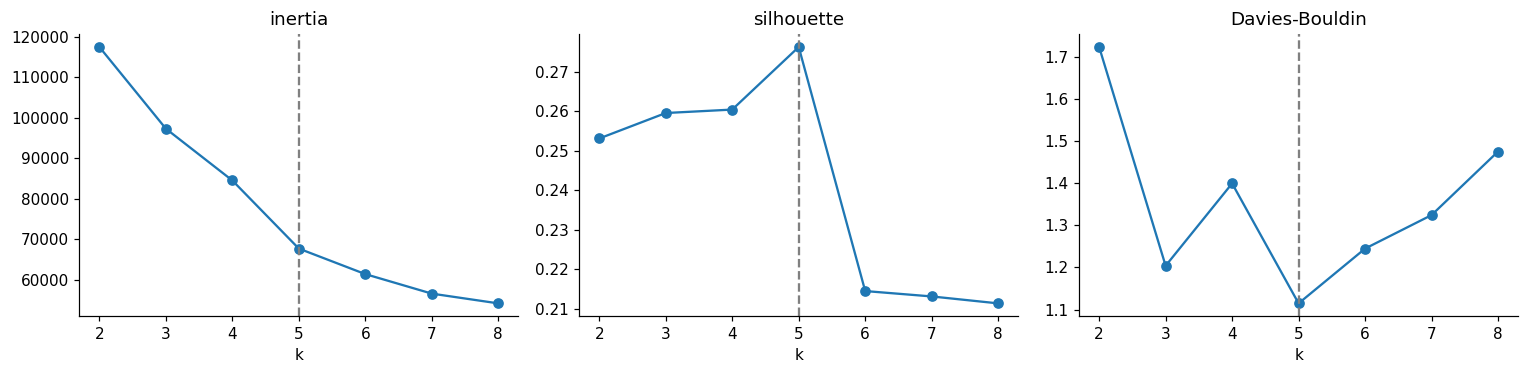

In [4]:
fig,ax=plt.subplots(1,3,figsize=(14,3.5))
for a,col in zip(ax,ks.columns):
    ks[col].plot(ax=a,marker='o');a.set_title(col);a.axvline(K,color='gray',ls='--')
plt.tight_layout();plt.show()

### 2.1 An average silhouette can hide poorly assigned cases
The silhouette diagram shows the spread within each group. Negative values mean that a case is closer on average to another group. Davies–Bouldin is better when lower, so it uses the opposite direction from silhouette.

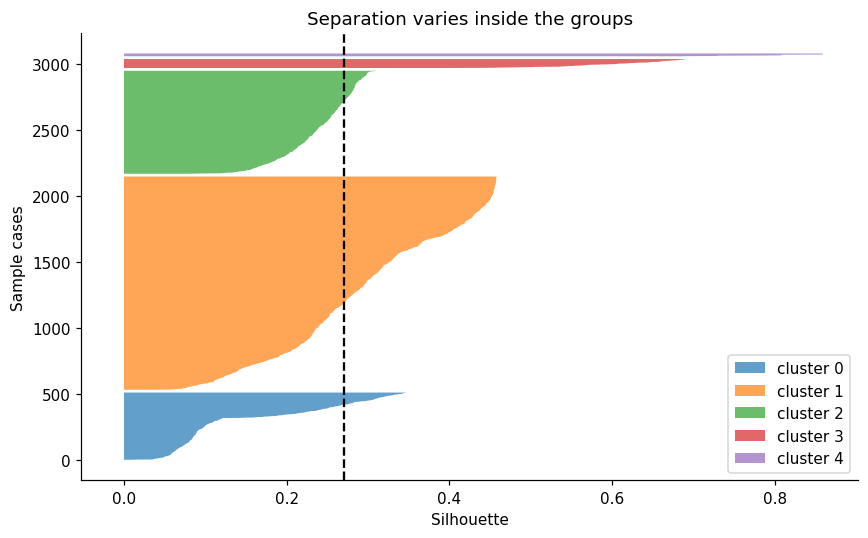

Negative sample silhouettes: 0.0%


In [5]:
sub=np.random.default_rng(SEED).choice(len(d),3000,replace=False)
point_silhouette=silhouette_samples(Xs[sub],km.labels_[sub])
fig,ax=plt.subplots(figsize=(8,5));bottom=0
for label in sorted(set(km.labels_[sub])):
    values=np.sort(point_silhouette[km.labels_[sub]==label]);top=bottom+len(values)
    ax.fill_betweenx(np.arange(bottom,top),0,values,alpha=.7,label=f'cluster {label}');bottom=top+20
ax.axvline(point_silhouette.mean(),color='black',ls='--');ax.set(xlabel='Silhouette',ylabel='Sample cases',title='Separation varies inside the groups')
ax.legend();plt.tight_layout();plt.show()
print(f'Negative sample silhouettes: {(point_silhouette<0).mean():.1%}')

## 3. Name the groups before calling them risk profiles
We summarize common building features. Damage is used only now, after fitting, to see whether groups differ in outcome. We compare that link with foundation alone.

,claims,foundation,occupancy,zone,median_coverage,claims_with_ratio,median_damage_ratio,rain_mm,neighborhood_income
cluster,,,,,,,,,
0,3370,slab,single family,AE,"250,000.000",2721,0.097,168.951,"82,955.000"
1,10921,slab,single family,AE,"250,000.000",8650,0.234,130.249,"92,798.000"
2,5057,slab,single family,AE,"250,000.000",4163,0.103,144.491,"80,688.000"
3,488,slab,unit in building,AE,0.000,11,0.000,133.293,"92,761.500"
4,164,slab,condo building,A,"89,600.000",140,0.383,139.744,"106,434.000"


NMI: clustering 0.017; foundation alone 0.081


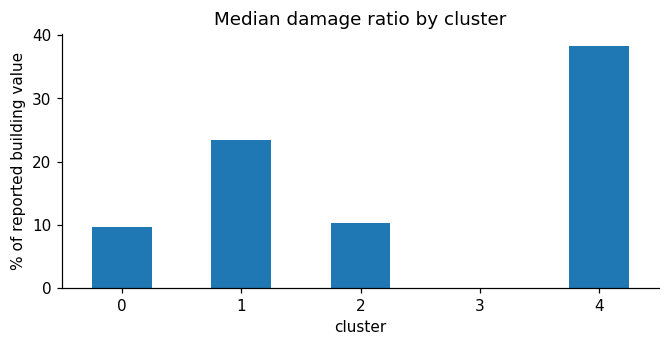

In [6]:
def mode(s): return s.mode().iloc[0] if s.notna().any() else 'unknown'
profile=d.groupby('cluster').agg(claims=('id','size'),foundation=('foundation_name',mode),
    occupancy=('occupancy_name',mode),zone=('zone',mode),median_coverage=('totalBuildingInsuranceCoverage','median'),
    claims_with_ratio=('damage_ratio','count'),median_damage_ratio=('damage_ratio','median'),
    rain_mm=('rain_5d_mm','median'),neighborhood_income=('median_household_income','median'))
display(profile.round(3))
known=d.severity_band.notna()
base_nmi=normalized_mutual_info_score(d.loc[known,'foundation'],d.loc[known,'severity_band'])
cluster_nmi=normalized_mutual_info_score(d.loc[known,'cluster'],d.loc[known,'severity_band'])
print(f'NMI: clustering {cluster_nmi:.3f}; foundation alone {base_nmi:.3f}')
profile.median_damage_ratio.mul(100).plot.bar(figsize=(7,3),title='Median damage ratio by cluster')
plt.ylabel('% of reported building value');plt.xticks(rotation=0);plt.show()
save_table(profile,'04_cluster_profiles')

**Decision.** A cluster name is a short summary, not a definition applying to every member. A slab-heavy group can contain other foundations. A difference in median damage also does not show a difference in flood probability, because every row already has a claim.

## 4. Try hierarchical clustering on the same sample
A dendrogram shows how groups merge. We draw only the final merges so the figure remains readable. Linkage is a distance rule between groups and can change the answer.

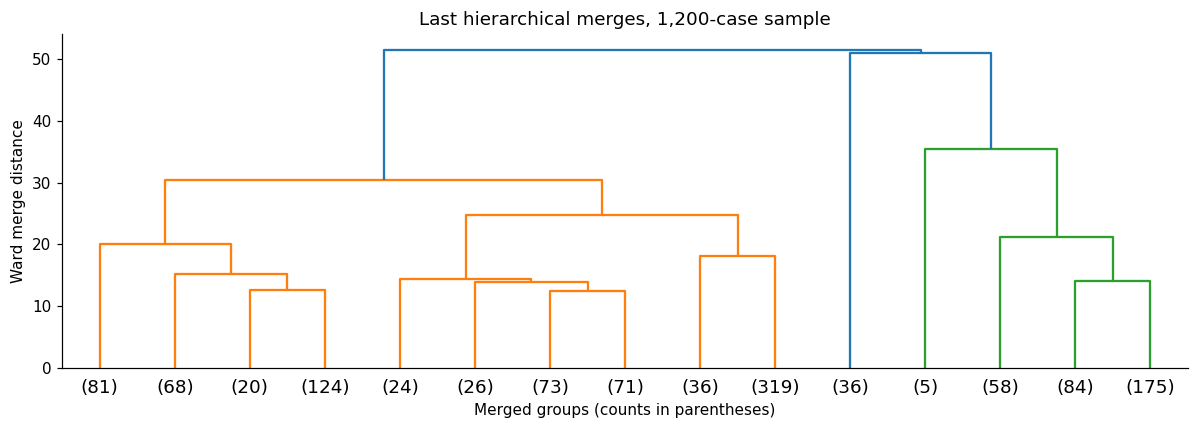

In [7]:
from scipy.cluster.hierarchy import linkage,dendrogram
hier_sub=np.random.default_rng(SEED).choice(len(d),1200,replace=False)
link=linkage(Xs[hier_sub],method='ward')
plt.figure(figsize=(11,4));dendrogram(link,truncate_mode='lastp',p=15,show_leaf_counts=True)
plt.xlabel('Merged groups (counts in parentheses)');plt.ylabel('Ward merge distance');plt.title('Last hierarchical merges, 1,200-case sample')
plt.tight_layout();plt.show()

### 4.1 Is the difference method or sample?
For this comparison, both k-means and hierarchical clustering are fitted on the same 4,000 cases. We compare Ward, average and complete linkage. ARI near zero means agreement near chance; one means identical assignments.

In [8]:
method_sub=np.random.default_rng(SEED).choice(len(d),4000,replace=False)
common=Xs[method_sub]
km_common=KMeans(n_clusters=K,n_init=10,random_state=SEED).fit_predict(common)
method_rows=[]
for method in ['ward','average','complete']:
    labels=AgglomerativeClustering(n_clusters=K,linkage=method).fit_predict(common)
    method_rows.append({'linkage':method,'silhouette':silhouette_score(common,labels,sample_size=2500,random_state=SEED),
                        'ARI with same-sample k-means':adjusted_rand_score(km_common,labels)})
display(pd.DataFrame(method_rows).set_index('linkage').round(3))

,silhouette,ARI with same-sample k-means
linkage,,
ward,0.225,0.767
average,0.320,0.133
complete,0.179,0.406


## 5. Test whether the answer survives resampling
Changing the seed tests sensitivity to initialization. Refitting on 80% of cases tests sensitivity to the sample. We compare assignments on the same reference cases after each refit. None of these tests uses damage to choose groups.

In [9]:
checks=[];rng=np.random.default_rng(SEED)
for seed in [7,21,84]:
    labels=KMeans(n_clusters=K,n_init=10,random_state=seed).fit_predict(Xs)
    checks.append({'change':f'initialization seed {seed}','ARI with reference':adjusted_rand_score(km.labels_,labels)})
    sample=rng.choice(len(d),int(.8*len(d)),replace=False)
    refit=KMeans(n_clusters=K,n_init=10,random_state=seed).fit(Xs[sample])
    checks.append({'change':f'80% refit {seed}','ARI with reference':adjusted_rand_score(km.labels_,refit.predict(Xs))})
stability=pd.DataFrame(checks).set_index('change');display(stability.round(3));save_table(stability,'04_stability')

,ARI with reference
change,
initialization seed 7,1.000
80% refit 7,1.000
initialization seed 21,1.000
80% refit 21,1.000
initialization seed 84,1.000
80% refit 84,1.000


**Why is the agreement exactly 1.000?** An ARI of 1 means the groups did not change at all. That is unusual for real data. It happens here because most inputs are yes/no codes (foundation, zone, building type). Claims with the same codes sit at exactly the same point, so the groups are built from a few common code combinations. This is *stable*, but it is not the same as finding natural classes. The noise test below helps to judge this.

### 5.1 Compare with an independent-column reference
Lecture 10 warns that algorithms return clusters even on noise. We independently shuffle each original input column, keeping its values but breaking cross-field relationships. This is a statistical reference, not realistic synthetic claims. Strong categories can still create apparent structure.

In [10]:
noise_data=d[cols].copy()
for col in noise_data:noise_data[col]=rng.permutation(noise_data[col].to_numpy())
noise_X=prep.transform(noise_data)
noise_labels=KMeans(n_clusters=K,n_init=10,random_state=SEED).fit_predict(noise_X)
noise_table=pd.DataFrame({'observed profiles':{'silhouette':silhouette_score(Xs,km.labels_,sample_size=3000,random_state=SEED),
                                              'Davies-Bouldin':davies_bouldin_score(Xs,km.labels_)},
                         'independent-column reference':{'silhouette':silhouette_score(noise_X,noise_labels,sample_size=3000,random_state=SEED),
                                                         'Davies-Bouldin':davies_bouldin_score(noise_X,noise_labels)}}).T
display(noise_table.round(3));save_table(noise_table,'04_noise_reference')

,silhouette,Davies-Bouldin
observed profiles,0.276,1.115
independent-column reference,0.255,1.181


**Decision.** A high score alone is not enough. We keep the group summaries as descriptive profiles only to the extent that they survive these checks and explain more than a simple known category. If the noise reference scores similarly, natural separation is weak evidence.

**Checkpoint · What the result changes**

Observed-profile silhouette is **0.276**, compared with **0.255** after breaking field relationships. The small difference warns that category frequencies and the chosen representation explain much of the apparent separation. Stability is useful, but it does not by itself prove natural flood-risk classes. Next we test PCA as another representation.

## 6. Does PCA improve the same grouping task?
We retain 80% of variation, refit the same k, and compare assignments. A similar silhouette with low ARI means we found different groups with similar average separation. It does not show that PCA recovered the true groups.

PCA keeps 7 of 33 encoded columns
ARI with reference: 1.0


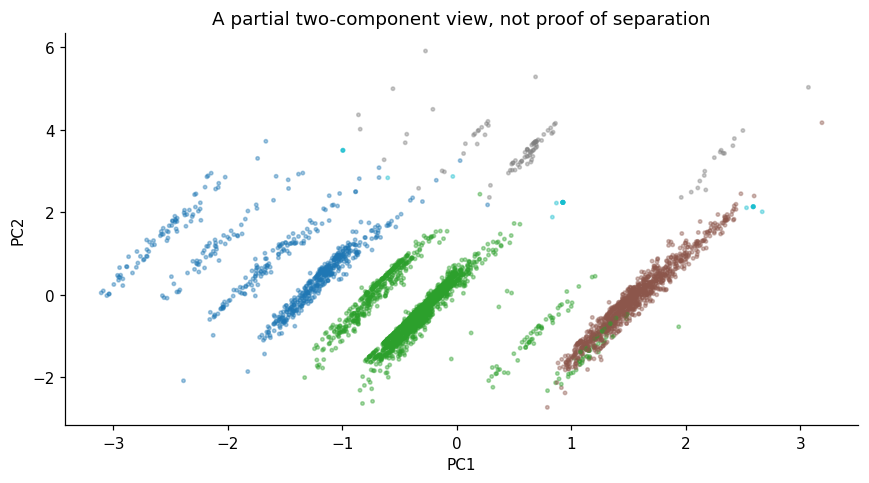

In [11]:
pca=PCA(n_components=.8,svd_solver='full').fit(Xs);Z=pca.transform(Xs)
pca_labels=KMeans(n_clusters=K,n_init=10,random_state=SEED).fit_predict(Z)
print(f'PCA keeps {pca.n_components_} of {Xs.shape[1]} encoded columns')
print('ARI with reference:',round(adjusted_rand_score(km.labels_,pca_labels),3))
projection=pca.transform(Xs)[:,:2]
sample=np.random.default_rng(SEED).choice(len(d),4000,replace=False)
plt.figure(figsize=(8,4.5));plt.scatter(projection[sample,0],projection[sample,1],c=km.labels_[sample],s=5,cmap='tab10',alpha=.4)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('A partial two-component view, not proof of separation');plt.tight_layout();plt.show()

## 7. Change the grouping assumption: DBSCAN
K-means assigns every case to a group. DBSCAN groups dense neighborhoods and can leave cases unassigned. We first inspect distances to the twentieth neighbor, then test three radii. A percentile is a sensitivity setting, not a proven elbow.

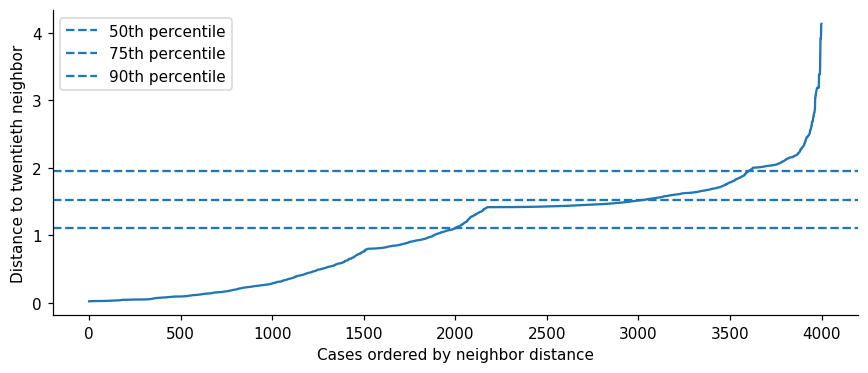

In [12]:
Xd=Xs[method_sub]
dist=NearestNeighbors(n_neighbors=20).fit(Xd).kneighbors(Xd)[0][:,-1]
plt.figure(figsize=(8,3.5));plt.plot(np.sort(dist))
for q in [50,75,90]:plt.axhline(np.percentile(dist,q),ls='--',label=f'{q}th percentile')
plt.xlabel('Cases ordered by neighbor distance');plt.ylabel('Distance to twentieth neighbor');plt.legend();plt.tight_layout();plt.show()

In [13]:
db_rows=[]
for q in [50,75,90]:
    eps=float(np.percentile(dist,q));labels=DBSCAN(eps=max(eps,1e-6),min_samples=20).fit_predict(Xd)
    keep=labels>=0;number=len(set(labels[keep]))
    score=silhouette_score(Xd[keep],labels[keep],sample_size=min(2500,keep.sum()),random_state=SEED) if 1<number<keep.sum() else np.nan
    db_rows.append({'radius percentile':q,'eps':eps,'groups':number,'unassigned share':(~keep).mean(),
                    'largest group share':pd.Series(labels[keep]).value_counts().max()/len(labels) if keep.any() else 0,
                    'silhouette assigned only':score})
display(pd.DataFrame(db_rows).set_index('radius percentile').round(3))

,eps,groups,unassigned share,largest group share,silhouette assigned only
radius percentile,,,,,
50,1.104,26,0.414,0.244,0.335
75,1.514,4,0.091,0.647,0.227
90,1.944,5,0.024,0.688,0.192


**Decision.** A higher DBSCAN silhouette after excluding many cases is not directly comparable with a score for every claim. Very small groups with identical codes can look dense without adding useful flood insight. Unassigned means unusual under this distance and radius, not an erroneous claim.

## 8. Add external sources only after understanding the building profiles
Rain and tracks can turn a building profile into an event profile. Census can turn it into a neighborhood profile. We hold k fixed to see how the meaning and separation change; damage remains outside fitting.

In [14]:
variants={'building profiles':cols,'profiles + hazards':cols+['rain_5d_mm','trk_dist_km','trk_wind_kt'],
          'profiles + Census':cols+CENSUS}
extra=[]
for name,cc in variants.items():
    XX=prepare(d[cc],scale=True).fit_transform(d[cc])
    lab=KMeans(n_clusters=K,n_init=10,random_state=SEED).fit_predict(XX)
    extra.append({'features':name,'silhouette':silhouette_score(XX,lab,sample_size=3000,random_state=SEED),
                  'NMI with severity':normalized_mutual_info_score(lab[known],d.loc[known,'severity_band']),
                  'ARI with building profiles':adjusted_rand_score(km.labels_,lab)})
extra=pd.DataFrame(extra).set_index('features');display(extra.round(3));save_table(extra,'04_feature_comparison')

,silhouette,NMI with severity,ARI with building profiles
features,,,
building profiles,0.276,0.017,1.000
profiles + hazards,0.272,0.032,0.616
profiles + Census,0.181,0.004,0.097


## 9. What did the sequence teach us?
The profiles summarize common combinations of building type, foundation and cover. Compare their severity link with foundation alone before claiming added value. If changing the seed or method changes the assignments, treat the groups as a useful summary rather than fixed natural classes.

Adding weather or Census data can reduce separation because claims vary along many overlapping directions. One-hot distances also depend on the number and choice of category columns. A stronger method would need profiles that remain useful across different samples and storms, not only a higher score on this sample.

Clustering does not show that a foundation causes damage. The buildings were hit in different places and conditions. A simple existing feature may explain severity as well as the new group labels.

In [15]:
display(Markdown(f"**Answer to RQ3.** The chosen {K}-group solution has silhouette **{ks.loc[K,'silhouette']:.3f}**. "
                 f"Its NMI with severity is **{cluster_nmi:.3f}**, compared with **{base_nmi:.3f}** for foundation alone. "
                 "These values and the agreement checks above show how much added structure the clusters provide."))

**Answer to RQ3.** The chosen 5-group solution has silhouette **0.276**. Its NMI with severity is **0.017**, compared with **0.081** for foundation alone. These values and the agreement checks above show how much added structure the clusters provide.

### 9.1 Decision ledger and bridge

| Step | What we checked | Why a step can be discarded |
|---|---|---|
| Raw vs scaled distance | Whether dollars dominate | Scale-defined groups may add little meaning |
| k and silhouette diagram | Whether groups separate internally | A good average can hide many poor assignments |
| Hierarchical/linkage | Whether another grouping rule agrees | Different rules can create different summaries |
| Seeds and 80% samples | Whether assignments are stable | An unstable label is weak evidence of a natural class |
| Independent-column reference | Whether structure exceeds an easy baseline | Categories can create apparent groups even without their original relationships |
| PCA | Whether fewer directions help | Variance retention is not a guarantee of meaningful groups |
| DBSCAN | Whether dense islands exist | Excluding cases can inflate the assigned-only score |
| Added sources | Whether extra context helps the intended profile | The question may change from buildings to events or neighborhoods |

**Bridge:** the next notebooks study specific patterns revealed by EDA and these profiles. Notebook 10 returns to density and unusual records. Notebook 11 asks whether readable association rules add more than a cluster label.

### Result in plain English

The largest group contains **54.6%** of the sample. Cluster median damage ratios range from **0.0%** to **38.3%**. These differences can describe building profiles, but they do not establish separate natural risk classes.

Compare method agreement, external-feature results and the foundation-only baseline. If a simple known category has a similar severity link, the cluster label adds limited information. Overlapping mixed building types and the chosen distance measure limit separation.